<a href="https://colab.research.google.com/github/mihirgohil1402-ui/Cfd-lab/blob/main/03_Centrifugal_Pump_SRF_vs_MRF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 3: Centrifugal Pump SRF vs MRF

**Name:** Mihir Gohil  |  **Roll No:** 23BME019  
**Course:** Computational Fluid Dynamics and Heat Transfer Lab (20ME406P), Department of Mechanical Engineering, PDEU


## 1. Aim
To compare the Single Rotating Frame (SRF) and Multiple Rotating Frames (MRF) formulations for a simplified centrifugal-pump passage, and to study how pump speed changes the pressure rise, the head, the velocity components and the temperature of the fluid.

## 2. Problem and parameters
This is a **reduced-order teaching model**, not a blade-resolved pump simulation. The flow passes radially outward through a flat annulus between two parallel walls, with the impeller blades represented only through the direction of the relative flow (a fixed blade angle). Three-dimensional effects, turbulence and blade-to-blade interaction are not modelled.

| Parameter | Symbol | Value |
|---|---|---|
| Inner radius (inlet) | r₁ | 0.030 m |
| Outer radius (outlet) | r₂ | 0.120 m |
| Passage depth | b | 0.010 m |
| Volume flow rate | Q | 2.0 × 10⁻⁴ m³/s |
| Fluid (water) density, viscosity | ρ, ν | 1000 kg/m³, 1.0 × 10⁻⁶ m²/s |
| Specific heat | c_p | 4180 J/(kg K) |
| Backward blade angle (from tangent) | β | 25° |
| Pump speeds | N | 1000, 2000, 3000 rpm |
| MRF interface radius | r_mrf | 0.080 m (rotor for r < r_mrf, stator beyond) |
| Inlet temperature, wall temperature | T_in, T_w | 300 K, 320 K |
| Wall heat-transfer coefficient | h_w | 500 W/(m² K) |
| Radial grid | n | 400 points |

## 3. Model
The radial velocity follows from continuity: u_r = Q / (2π r b).

**SRF.** The whole annulus is treated in a frame rotating at Ω together with the blades. The relative flow follows the blades, so the relative tangential velocity is w_θ = −u_r / tan β (β measured from the tangent, backward-curved blades). The absolute tangential velocity is c_θ = Ωr + w_θ. Conservation of rothalpy in the rotating frame, with a laminar loss for a narrow gap, gives the static pressure:
$$\frac{p}{\rho} + \frac{w^2}{2} - \frac{\Omega^2 r^2}{2} + \int_{r_1}^{r}\frac{12\nu\,u_r}{b^2}\,dr = \text{const}, \qquad w^2 = u_r^2 + w_\theta^2$$
The loss term 12 ν u_r / b² is the viscous force per unit mass in the gap between two parallel walls.

**MRF.** The annulus is split at r_mrf. The rotor zone (r < r_mrf) is solved in the rotating frame exactly as in the SRF model. The stator zone (r > r_mrf) is solved in the stationary frame as a **vaneless diffuser**: the absolute tangential velocity follows angular-momentum conservation, c_θ r = const (equal to its value at the interface), and the absolute Bernoulli equation holds, p/ρ + c²/2 + loss = const. At the interface the absolute velocity is passed from the rotor to the stator (this is the frozen-rotor interface assumption of MRF).

**Temperature.** Fluid exchanges heat with the two walls: u_r dT/dr = −β_T (T − T_w), with β_T = 2h_w/(ρ c_p b). Viscous heating is neglected.

**Head** is H = Δp/(ρ g) with Δp = p(r₂) − p(r₁) and gauge pressure p(r₁) = 0.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

r1, r2, b = 0.030, 0.120, 0.010
Q = 2.0e-4
rho, nu, cp, g = 1000.0, 1.0e-6, 4180.0, 9.81
beta_blade = np.radians(25.0)
r_mrf = 0.080
T_in, T_w, h_w = 300.0, 320.0, 500.0
n = 400
r = np.linspace(r1, r2, n)

def trapz_cum(f, x):
    """Cumulative trapezoidal integral of f(x) from x[0]."""
    out = np.zeros_like(x)
    out[1:] = np.cumsum(0.5*(f[1:] + f[:-1])*np.diff(x))
    return out

def pump(rpm, model, r_m=r_mrf):
    Om = 2*np.pi*rpm/60
    ur = Q/(2*np.pi*r*b)
    loss_rate = 12*nu*ur/b**2                       # viscous loss per unit mass per unit length
    loss = trapz_cum(loss_rate, r)
    # ---- rotor (rotating-frame) quantities everywhere ----
    w_th = -ur/np.tan(beta_blade)                   # relative tangential velocity (backward blades)
    w2 = ur**2 + w_th**2
    c_th_rot = Om*r + w_th                          # absolute tangential velocity if blades extended to r
    p_rot = rho*(0.5*Om**2*(r**2 - r1**2) - 0.5*(w2 - w2[0]) - loss)
    if model == 'SRF':
        c_th = c_th_rot
        p = p_rot
        zone = np.full(n, Om)
    else:
        i_m = np.argmin(abs(r - r_m))
        c_th = c_th_rot.copy()
        p = p_rot.copy()
        zone = np.where(r <= r[i_m], Om, 0.0)
        # stator zone: vaneless diffuser, c_theta * r = const, absolute Bernoulli
        c_th[i_m:] = c_th_rot[i_m]*r[i_m]/r[i_m:]
        c2 = ur**2 + c_th**2
        p[i_m:] = p_rot[i_m] - rho*(0.5*(c2[i_m:] - c2[i_m]) + (loss[i_m:] - loss[i_m]))
        w_th = np.where(r <= r[i_m], w_th, c_th - 0.0)   # in the stator zone the relative frame is the absolute frame
    # ---- temperature ----
    beta_T = 2*h_w/(rho*cp*b)
    T = T_w - (T_w - T_in)*np.exp(-beta_T*trapz_cum(1/ur, r))      # integral of dr/u_r by the trapezoidal rule
    return dict(rpm=rpm, Om=Om, ur=ur, w_th=w_th, c_th=c_th, p=p, T=T,
                dp=p[-1]-p[0], head=(p[-1]-p[0])/(rho*g), model=model)

## 4. Run SRF and MRF at three speeds

In [ ]:
rows = []
sols = {}
for rpm in (1000, 2000, 3000):
    for mdl in ('SRF', 'MRF'):
        s = pump(rpm, mdl)
        sols[(rpm, mdl)] = s
        rows.append([rpm, mdl, s['dp']/1e3, s['head'], s['c_th'][-1], s['T'][-1]])
pd.DataFrame(rows, columns=['rpm', 'model', 'pressure rise (kPa)', 'head (m)', 'c_theta at outlet (m/s)', 'T outlet (K)'])

,rpm,model,pressure rise (kPa),head (m),c_theta at outlet (m/s),T outlet (K)
0,1000,SRF,74.051050,7.548527,12.509486,300.989322
1,1000,MRF,49.358393,5.031437,5.538672,300.989322
2,2000,SRF,296.117149,30.185234,25.075856,300.989322
3,2000,MRF,198.139590,20.197716,11.134229,300.989322
4,3000,SRF,666.227314,67.913080,37.642227,300.989322
5,3000,MRF,446.372607,45.501795,16.729785,300.989322


## 5. Profiles along the radius

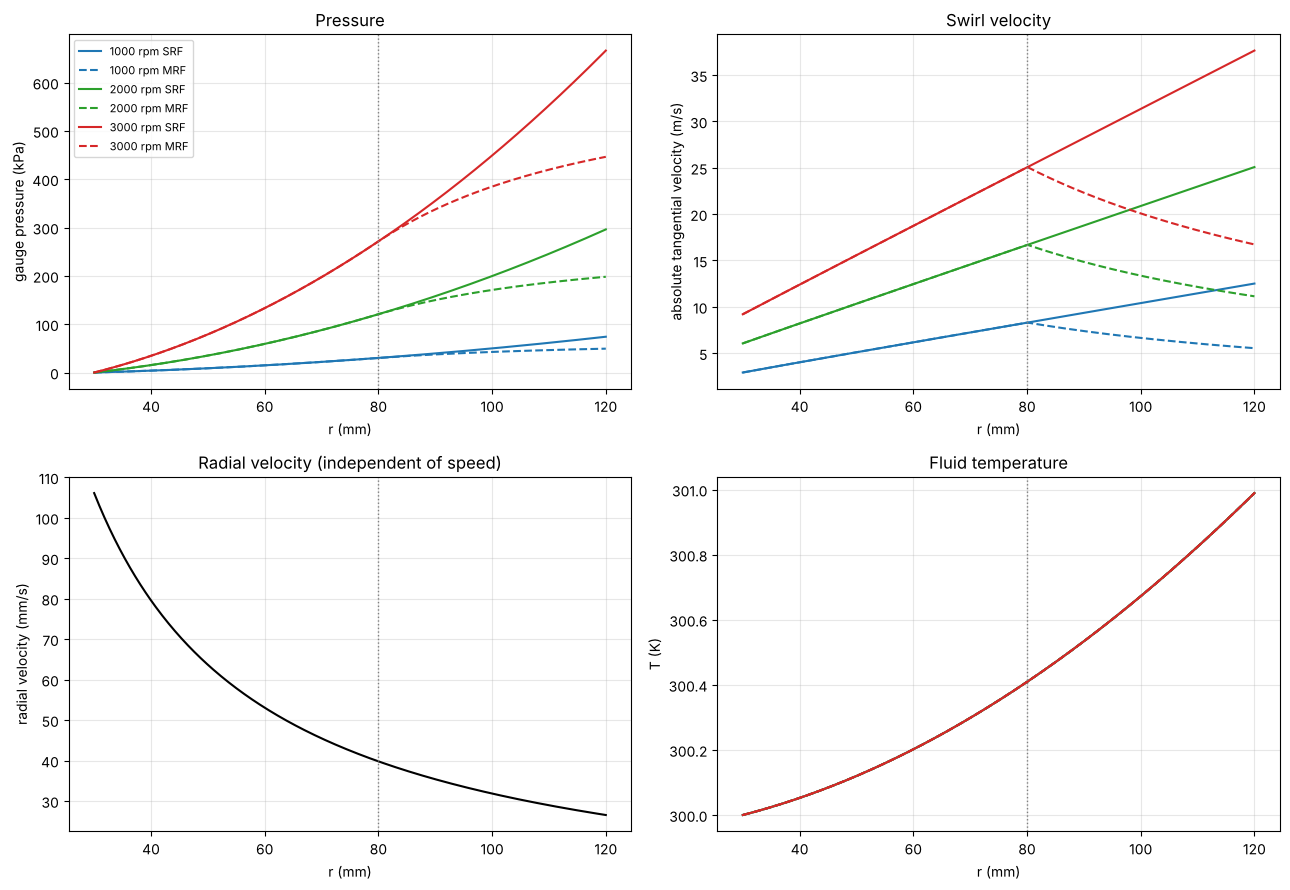

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
cols = {1000: 'tab:blue', 2000: 'tab:green', 3000: 'tab:red'}
for rpm in (1000, 2000, 3000):
    for mdl, ls in (('SRF', '-'), ('MRF', '--')):
        s = sols[(rpm, mdl)]
        ax[0, 0].plot(r*1e3, s['p']/1e3, ls, color=cols[rpm], label=f'{rpm} rpm {mdl}')
        ax[0, 1].plot(r*1e3, s['c_th'], ls, color=cols[rpm])
        ax[1, 1].plot(r*1e3, s['T'], ls, color=cols[rpm])
ax[1, 0].plot(r*1e3, sols[(1000, 'SRF')]['ur']*1e3, 'k-')
ax[0, 0].set(xlabel='r (mm)', ylabel='gauge pressure (kPa)', title='Pressure'); ax[0, 0].legend(fontsize=8)
ax[0, 1].set(xlabel='r (mm)', ylabel='absolute tangential velocity (m/s)', title='Swirl velocity')
ax[1, 0].set(xlabel='r (mm)', ylabel='radial velocity (mm/s)', title='Radial velocity (independent of speed)')
ax[1, 1].set(xlabel='r (mm)', ylabel='T (K)', title='Fluid temperature')
for a in ax.ravel():
    a.axvline(r_mrf*1e3, color='gray', ls=':', lw=1); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The dotted vertical line is the MRF interface radius.

## 6. Head versus speed and the effect of the interface radius

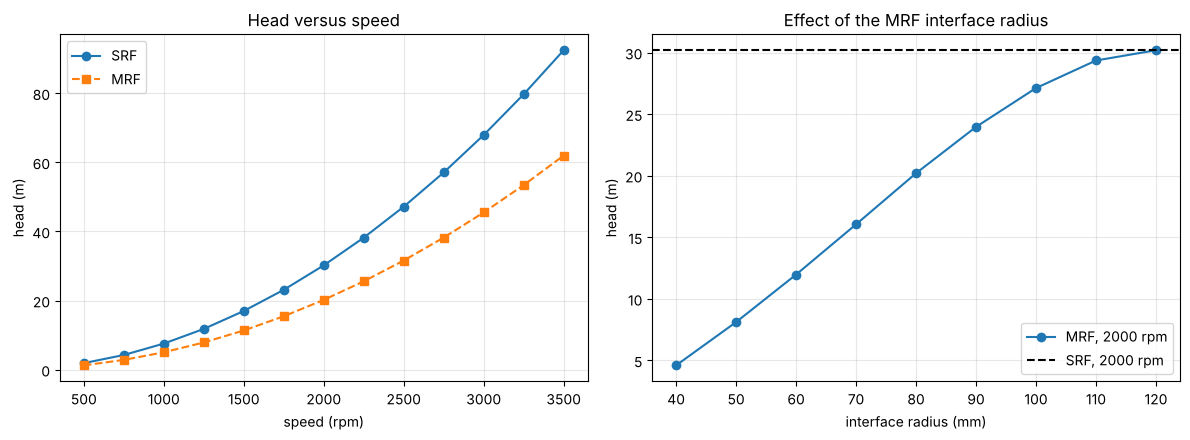

,rpm,SRF head (m),MRF head (m),MRF / SRF
0,500,1.889350,1.249972,0.661588
1,750,4.247340,2.823898,0.664863
2,1000,7.548527,5.031437,0.666545
3,1250,11.792910,7.872588,0.667570
4,1500,16.980488,11.347351,0.668258
5,1750,23.111263,15.455727,0.668753
6,2000,30.185234,20.197716,0.669126
7,2250,38.202402,25.573317,0.669416
8,2500,47.162765,31.582530,0.669650
9,2750,57.066324,38.225356,0.669841


In [ ]:
rpms = np.arange(500, 3501, 250)
H_srf = [pump(n_, 'SRF')['head'] for n_ in rpms]
H_mrf = [pump(n_, 'MRF')['head'] for n_ in rpms]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(rpms, H_srf, 'o-', label='SRF'); ax[0].plot(rpms, H_mrf, 's--', label='MRF')
ax[0].set(xlabel='speed (rpm)', ylabel='head (m)', title='Head versus speed'); ax[0].legend(); ax[0].grid(alpha=0.3)

r_list = np.linspace(0.04, 0.12, 9)
heads = [pump(2000, 'MRF', r_m=rm)['head'] for rm in r_list]
ax[1].plot(r_list*1e3, heads, 'o-', label='MRF, 2000 rpm')
ax[1].axhline(pump(2000, 'SRF')['head'], color='k', ls='--', label='SRF, 2000 rpm')
ax[1].set(xlabel='interface radius (mm)', ylabel='head (m)', title='Effect of the MRF interface radius'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# head ratio table
pd.DataFrame({'rpm': rpms, 'SRF head (m)': H_srf, 'MRF head (m)': H_mrf, 'MRF / SRF': np.array(H_mrf)/np.array(H_srf)})